**1. Introducción**

Este notebook tiene como objetivo explorar y analizar un conjunto de datos que contiene detalles exhaustivos sobre libros, incluyendo su título, autor, calificación promedio, número de calificaciones y reseñas, una breve descripción y los géneros a los que pertenece. El análisis de esta información nos permitirá descubrir patrones y obtener información valiosa sobre la literatura y las preferencias de los lectores.

**Fuente y Contexto**

El conjunto de datos utilizado para este análisis fue descargado de Kagglehub, bajo el nombre "Books Details Dataset".

**Preguntas Guía para el Análisis**


1. Cómo se distribuyen los libros en los diferentes géneros y cuáles son los más predominantes en el dataset?
2. Existe una relación entre el número de calificaciones y el número de reseñas con la calificación general promedio de un libro?
3. Quiénes son los autores más populares en el dataset, y qué características comparten sus libros mejor valorados en términos de género y recepción?

**2. Exploración inicial**

A continución, se realiza la desacarga del dataset desde Kagglehub y se carga del dataset en un DataFrame de pandas. Luego se realiza una exploración inicial para comprender su estructura, verificar el número de registros y columnas, e identificar posibles problemas.


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import numpy as np

plt.style.use('seaborn-v0_8')
sns.set_palette('muted')

dataset_path = kagglehub.dataset_download('deepaktheanalyst/books-details-dataset')
print(f"Dataset descargado en: {dataset_path}")

Using Colab cache for faster access to the 'books-details-dataset' dataset.
Dataset descargado en: /kaggle/input/books-details-dataset


In [5]:
dataset_path = '/kaggle/input/books-details-dataset/book_details.csv'
df = pd.read_csv(dataset_path, encoding='latin1')

In [6]:
print("DataFrame Head: ")
print(df.head())

print("\n DataFrame Info: ")
df.info()

print("\n Estadísticas descriptivas: ")
print(df.describe())

print("\n Filas y Columnas: ")
print(df.shape)

print("\n Nombres de Columnas: ")
print(df.columns.tolist())

print("\n Tipos de datos de cada Columna: ")
print(df.dtypes)

DataFrame Head: 
                    title           author  rating  no_of_ratings  \
0               Divergent    Veronica Roth    4.15        3765886   
1           Catching Fire  Suzanne Collins    4.31        3305054   
2  The Fault in Our Stars       John Green    4.15        4851513   
3   To Kill a Mockingbird       Harper Lee    4.27        5784553   
4     The Lightning Thief     Rick Riordan    4.30        2752945   

  no_of_reviews                                        description  \
0       117,791  In Beatrice Prior's dystopian Chicago world, s...   
1       113,480  Sparks are igniting.Flames are spreading.And t...   
2       174,662  Despite the tumor-shrinking medical miracle th...   
3       112,055  The unforgettable novel of a childhood in a sl...   
4        87,446  Alternate cover for this ISBN can be found her...   

                                              genres  
0  Young Adult, Dystopia, Fantasy, Fiction, Scien...  
1  Young Adult, Dystopia, Fiction, Fa

**3.Limpieza y tratamiento de datos**

El objetivo es identificar y tratar valores faltantes, detectar y eliminar filas duplicadas, y corregir formatos o tipos de datos, en caso de ser necesario.



Pude observar que la columna no_of_reviews es de tipo object pero en la descripcion del dataset dice que es "El número total de reseñas que el libro ha recibido en Goodreads". Así que decidí primero convertirla a String, eliminar las comas, también los espacios en blanco (por si alguna los tenía) y convertirla a formato numérico (int64).

In [7]:
df['no_of_reviews'] = df['no_of_reviews'].astype(str)

df['no_of_reviews'] = df['no_of_reviews'].str.replace(',', '', regex=False)
df['no_of_reviews'] = df['no_of_reviews'].str.strip()
df['no_of_reviews'] = pd.to_numeric(df['no_of_reviews'])

print("\n Info después de la conversión de 'no_of_reviews': ")
df.info()
print("\n Head después de la conversión: ")
print(df.head())


 Info después de la conversión de 'no_of_reviews': 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13324 entries, 0 to 13323
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   title          13324 non-null  object 
 1   author         13324 non-null  object 
 2   rating         13324 non-null  float64
 3   no_of_ratings  13324 non-null  int64  
 4   no_of_reviews  13324 non-null  int64  
 5   description    13273 non-null  object 
 6   genres         12327 non-null  object 
dtypes: float64(1), int64(2), object(4)
memory usage: 728.8+ KB

 Head después de la conversión: 
                    title           author  rating  no_of_ratings  \
0               Divergent    Veronica Roth    4.15        3765886   
1           Catching Fire  Suzanne Collins    4.31        3305054   
2  The Fault in Our Stars       John Green    4.15        4851513   
3   To Kill a Mockingbird       Harper Lee    4.27        5784553   


In [8]:
print("Valores nulos por columna: ")
print(df.isnull().sum())

Valores nulos por columna: 
title              0
author             0
rating             0
no_of_ratings      0
no_of_reviews      0
description       51
genres           997
dtype: int64


In [9]:
print(f"Número de filas duplicadas: {df.duplicated().sum()}")


Número de filas duplicadas: 0


In [10]:
print(f"Número de títulos duplicados: {df['title'].duplicated().sum()}")

duplicate_titles = df[df['title'].duplicated(keep=False)].sort_values(by='title')
if not duplicate_titles.empty:
    print("\nFilas con títulos duplicados:")
    display(duplicate_titles)
else:
    print("\nNo se encontraron títulos duplicados.")

Número de títulos duplicados: 0

No se encontraron títulos duplicados.


In [11]:
df['description'] = df['description'].fillna('Sin Descripción')
print("\n Valores nulos después de imputar la columna 'description': \n")
print(df.isnull().sum())


 Valores nulos después de imputar la columna 'description': 

title              0
author             0
rating             0
no_of_ratings      0
no_of_reviews      0
description        0
genres           997
dtype: int64


**Imputación de Valores Nulos en la Columna 'genres'**

Dado que un libro puede tener múltiples géneros, imputar un solo género a todos los nulos podría simplificar demasiado la realidad y no ser representativo. Si un libro tiene, por ejemplo, 'Young Adult, Dystopia', y la moda es 'Fiction', al imputar solo 'Fiction' se podría perder información valiosa.

Por eso, la estrategia más directa y segura es imputar los valores nulos como **'Género Desconocido'**. Esto permite mantener las filas y reconocer explícitamente la ausencia de información de género de manera transparente en los análisis y gráficos posteriores.

In [12]:
df['genres'] = df['genres'].fillna('Género Desconocido')

print("Valores nulos después de imputar la columna 'genres':")
print(df.isnull().sum())

Valores nulos después de imputar la columna 'genres':
title            0
author           0
rating           0
no_of_ratings    0
no_of_reviews    0
description      0
genres           0
dtype: int64


**4. Transformaciones**

Para poder responder con este análisis a las preguntas iniciales, primero se renombrarán las columnas 'no_of_ratings' y 'no_of_reviews' para mejorar la claridad y consistencia en los nombres de dichas columnas.

In [13]:
df.rename(columns={'no_of_ratings': 'num_of_ratings', 'no_of_reviews': 'num_of_reviews'}, inplace=True)

print("Nombres de columnas después de renombrar: \n")
print(df.columns.tolist())

Nombres de columnas después de renombrar: 

['title', 'author', 'rating', 'num_of_ratings', 'num_of_reviews', 'description', 'genres']


Debido a que la columna 'genres' tiene múltiples géneros separados por comas, primero transformo dicha columna en una **lista de Python** para cada fila. Luego, aplico `.explode()` para expandir el DataFrame con el objetivo de facilitar el análisis.

Luego de extraer cada género individualmente se cuenta su frecuencia para facilitar la respuesta a la primer pregunta guía (Cómo se distribuyen los libros en los diferentes géneros y cuáles son los más predominantes en el dataset?).

In [14]:

df_exploded = df.copy()

# Cadena de géneros a listas de Python (limpiando espacios en blanco)
df_exploded['genres_list'] = df_exploded['genres'].apply(lambda x: [g.strip() for g in str(x).split(',') if g.strip()])

df_exploded = df_exploded.explode('genres_list')

# Renombro la columna para mayor claridad
df_exploded.rename(columns={'genres_list': 'individual_genre'}, inplace=True)


print("Estructura del DataFrame tras aplicar explode(): ")
display(df_exploded[['title', 'author', 'individual_genre']].head(10))

Estructura del DataFrame tras aplicar explode():


,title,author,individual_genre
0,Divergent,Veronica Roth,Young Adult
0,Divergent,Veronica Roth,Dystopia
0,Divergent,Veronica Roth,Fantasy
0,Divergent,Veronica Roth,Fiction
0,Divergent,Veronica Roth,Science Fiction
0,Divergent,Veronica Roth,Romance
0,Divergent,Veronica Roth,Adventure
1,Catching Fire,Suzanne Collins,Young Adult
1,Catching Fire,Suzanne Collins,Dystopia
1,Catching Fire,Suzanne Collins,Fiction


In [15]:
# Conteo de la frecuencia de cada género
genres_counts_new = df_exploded['individual_genre'].value_counts().reset_index()
genres_counts_new.columns = ['Genre', 'Cantidad']

print("Los 20 géneros más predominantes:")
display(genres_counts_new.head(20))

Los 20 géneros más predominantes:


,Genre,Cantidad
0,Fiction,7221
1,Romance,4332
2,Fantasy,3369
3,Contemporary,2841
4,Young Adult,2593
5,Nonfiction,2210
6,Mystery,2186
7,Historical Fiction,1821
8,Audiobook,1782
9,Classics,1567


Para responder a la pregunta sobre los autores más populares y las características de sus libros mejor valorados, seguiremos un proceso de agrupación y sumarización, considerando la popularidad de un autor basándonos en la suma total de la columna 'num_of_ratings' (número total de calificaciones) recibidos por todos sus libros.

Luego de obtener la lista de autores, se analizan los géneros y calificaciones de sus libros que tienen las mejores valoraciones ('rating' mayor a 4.0, considerando que el máximo es 5.0)

In [16]:
import pandas as pd

autor_popular = df.groupby('author')['num_of_ratings'].sum().sort_values(ascending=False)

print("Los 10 autores más populares son: \n")
display(autor_popular.head(10))


cant_libros = df['author'].value_counts()
print("\n Cantidad de libros por los 10 autores más populares: \n")
display(cant_libros.loc[autor_popular.head(10).index])

Los 10 autores más populares son: 



,num_of_ratings
author,
Suzanne Collins,22836910
J.K. Rowling,22826043
Colleen Hoover,11969606
Stephen King,11305109
Rick Riordan,10907810
John Green,9857607
Sarah J. Maas,8883683
Dan Brown,8095186
J.R.R. Tolkien,7793636



 Cantidad de libros por los 10 autores más populares: 



,count
author,
Suzanne Collins,6
J.K. Rowling,11
Colleen Hoover,17
Stephen King,48
Rick Riordan,22
John Green,9
Sarah J. Maas,15
Dan Brown,7
J.R.R. Tolkien,8


In [18]:
import collections

top_5= autor_popular.head(5).index.tolist()

print("Análisis de libros mejor valorados para los 5 autores más populares: \n")

for autor in top_5:
    autor_libros = df[df['author'] == autor]
    mejores_libros = autor_libros[autor_libros['rating'] > 4.0].sort_values(by='rating', ascending=False)

    if not mejores_libros.empty:
        print(f"--- Autor: {autor} ---")
        print(f"Número de libros mejor valorados: {len(mejores_libros)}")
        display(mejores_libros[['title', 'rating', 'genres', 'num_of_ratings', 'num_of_reviews']].head())


        generos_autor = []
        for genres_str in mejores_libros['genres']:
            if pd.notna(genres_str):
                generos = [genre.strip() for genre in genres_str.split(',') if genre.strip()]
                generos_autor.extend(generos)

        if generos_autor:
            generos_cant = collections.Counter(generos_autor)
            print("\n Géneros predominantes en sus libros mejor valorados: \n")
            display(pd.DataFrame(generos_cant.most_common(5), columns=['Género', 'Cantidad']))
        else:
            print("No se encontraron géneros para los libros mejor valorados de este autor")
        print("\n" + "-"*50 + "\n")
    else:
        print(f"--- Autor: {autor} ---")
        print("\n No tiene libros con calificación superior a 4.0 en el dataset")
        print("\n" + "-"*50 + "\n")

Análisis de libros mejor valorados para los 5 autores más populares: 

--- Autor: Suzanne Collins ---
Número de libros mejor valorados: 6


,title,rating,genres,num_of_ratings,num_of_reviews
7790,The Hunger Games Trilogy Boxset,4.49,"Young Adult, Fiction, Fantasy, Dystopia, Scien...",214285,7262
11510,Hungerspelen,4.33,"Young Adult, Fiction, Dystopia, Fantasy, Scien...",8104716,201296
12124,The Hunger Games,4.33,"Young Adult, Fiction, Dystopia, Fantasy, Scien...",8104716,201296
1,Catching Fire,4.31,"Young Adult, Dystopia, Fiction, Fantasy, Scien...",3305054,113480
6883,Mockingjay,4.07,"Young Adult, Dystopia, Fiction, Fantasy, Scien...",3005909,119299



 Géneros predominantes en sus libros mejor valorados: 



,Género,Cantidad
0,Young Adult,6
1,Fiction,6
2,Fantasy,6
3,Adventure,6
4,Dystopia,5



--------------------------------------------------

--- Autor: J.K. Rowling ---
Número de libros mejor valorados: 8


,title,rating,genres,num_of_ratings,num_of_reviews
35,Harry Potter Series Box Set,4.74,"Fantasy, Young Adult, Fiction, Magic, Children...",280824,8156
10293,Harry Potter and the Deathly Hallows,4.62,"Fantasy, Young Adult, Fiction, Magic, Children...",3519250,80816
11,Harry Potter and the Half-Blood Prince,4.58,"Fantasy, Young Adult, Fiction, Magic, Children...",3097921,53323
5,Harry Potter and the Prisoner of Azkaban,4.58,"Fantasy, Fiction, Young Adult, Magic, Children...",3889833,77063
6900,Harry Potter and the Goblet of Fire,4.56,"Fantasy, Young Adult, Fiction, Magic, Children...",3462958,63756


... (11 outputs left out)

,title,rating,genres,num_of_ratings,num_of_reviews
12361,The House of Hades,4.56,"Fantasy, Mythology, Young Adult, Middle Grade,...",376425,20059
4728,The Last Olympian,4.54,"Fantasy, Young Adult, Mythology, Fiction, Midd...",915791,35306
10466,The Mark of Athena,4.47,"Fantasy, Mythology, Young Adult, Fiction, Midd...",560139,22458
11515,Percy Jackson and the Greek Gods (English),4.45,"Fantasy, Mythology, Young Adult, Middle Grade,...",77076,4787
13143,Percy Jackson's Greek Gods,4.45,"Fantasy, Mythology, Young Adult, Middle Grade,...",77077,4787



 Géneros predominantes en sus libros mejor valorados: 



,Género,Cantidad
0,Mythology,21
1,Young Adult,21
2,Middle Grade,21
3,Fiction,21
4,Adventure,21



--------------------------------------------------



**5. Visualización**

Para una mejor comprensión visual, se realizaron gráficos de barras de los 15 géneros principales y del total de calificaciones (num_of_ratings) para los 10 autores principales. Esto proporciona una visión rápida de la magnitud de su popularidad.

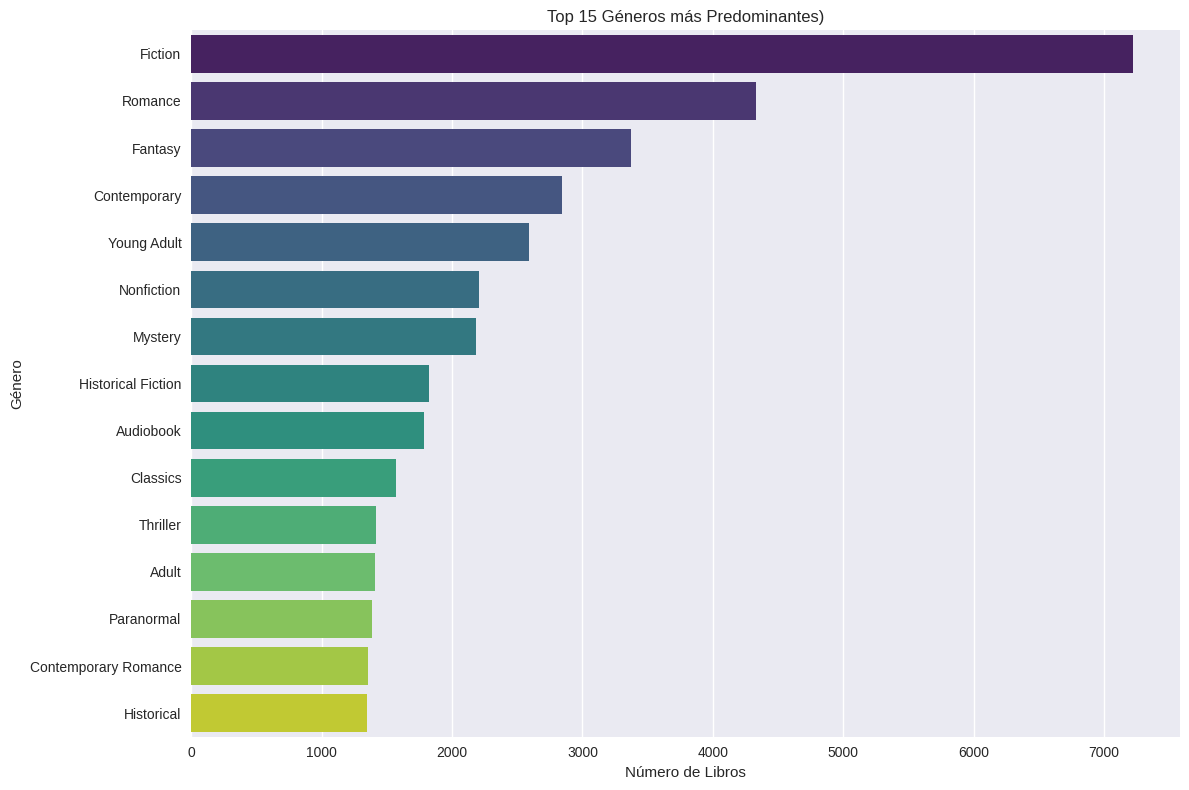

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns


top_n_generos = 15
genres_data_to_plot = df_exploded['individual_genre'].value_counts().head(top_n_generos).reset_index()
genres_data_to_plot.columns = ['Genre', 'Cantidad']


plt.figure(figsize=(12, 8))
sns.barplot(x='Cantidad', y='Genre', data=genres_data_to_plot, hue='Genre', palette='viridis', legend=False)
plt.title(f'Top {top_n_generos} Géneros más Predominantes)')
plt.xlabel('Número de Libros')
plt.ylabel('Género')
plt.tight_layout()
plt.show()

/tmp/ipykernel_1525/1669445584.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='num_of_ratings', y='author', data=top_10_autores, palette='viridis')


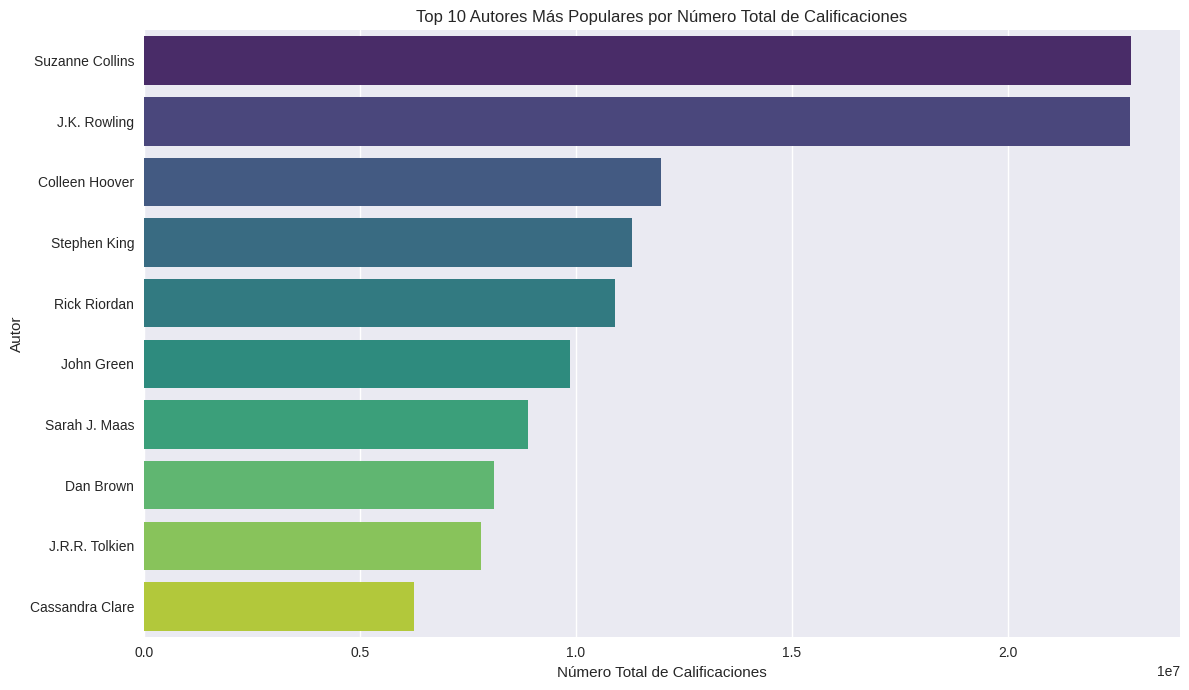

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

top_10_autores= autor_popular.head(10).reset_index()

plt.figure(figsize=(12, 7))
sns.barplot(x='num_of_ratings', y='author', data=top_10_autores, palette='viridis')
plt.title('Top 10 Autores Más Populares por Número Total de Calificaciones')
plt.xlabel('Número Total de Calificaciones')
plt.ylabel('Autor')
plt.tight_layout()
plt.show()

Para poder responder correctamente a la segunda pregunta guía (Existe una relación entre el número de calificaciones y el número de reseñas con la calificación general promedio de un libro?), decidí realizar una matriz de correlación entre las columnas 'rating',  'num_of_ratings' y 'num_of_reviews'

Matriz de Correlación:


,rating,num_of_ratings,num_of_reviews
rating,1.000000,0.036426,0.028510
num_of_ratings,0.036426,1.000000,0.812808
num_of_reviews,0.028510,0.812808,1.000000


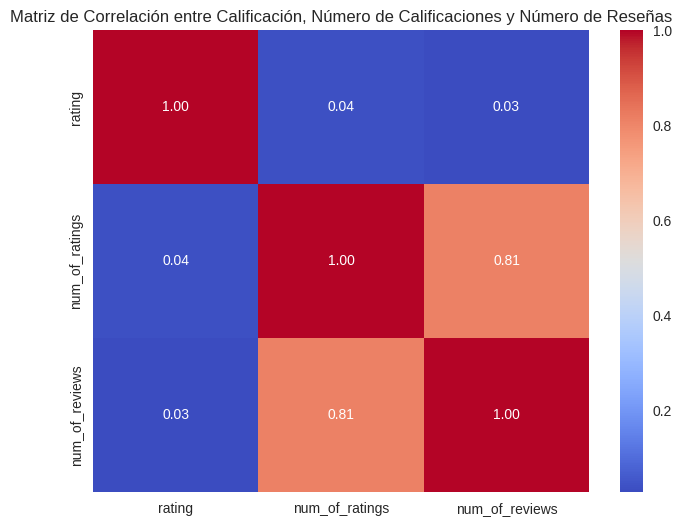

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt

correlacion_columnas = ['rating', 'num_of_ratings', 'num_of_reviews']


correlacion_matriz = df[correlacion_columnas].corr()

print("Matriz de Correlación:")
display(correlacion_matriz)

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion_matriz, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación entre Calificación, Número de Calificaciones y Número de Reseñas')
plt.show()

6. Conclusiones

**Respuestas a las Preguntas Guía**

**Cómo se distribuyen los libros en los diferentes géneros y cuáles son los más predominantes en el dataset?**

El análisis de la columna 'genres' reveló una rica diversidad de géneros, aunque con una clara predominancia de algunos. Los géneros más comunes en el dataset son:

*   **Ficción**
*   **Romance**
*   **Fantasía**
*   **Contemporáneo**
*   **Young Adult (Literatura Juvenil)**

Esta distribución indica que el dataset está fuertemente sesgado hacia la literatura popular y de entretenimiento, con un énfasis significativo en la ficción. La presencia de 'Género Desconocido' también sugiere que una parte de los libros no tenía una clasificación de género explícita, lo cual fue manejado mediante la imputación.

**Existe una relación entre el número de calificaciones y el número de reseñas con la calificación general promedio de un libro?**

El análisis de correlación y la matriz mostraron lo siguiente:

*   **Correlación entre 'rating' y 'num_of_ratings' (0.04) / 'num_of_reviews' (0.03):** La correlación entre la calificación promedio de un libro y el número de calificaciones o reseñas es **muy baja**.
Esto indica que un mayor volumen de interacciones (más calificaciones o reseñas) no implica necesariamente una calificación promedio más alta o más baja. Un libro puede ser muy popular (muchas calificaciones/reseñas) y tener una calificación promedio moderada, y viceversa.
*   **Correlación entre 'num_of_ratings' y 'num_of_reviews' (0.81):** Existe una **correlación positiva fuerte** y significativa entre el número de calificaciones y el número de reseñas. Esto es intuitivo, ya que los libros que generan muchas calificaciones también suelen generar muchas reseñas, lo que sugiere que ambas métricas son buenos indicadores de la popularidad general o el nivel de participación de los lectores con un libro.

En resumen, la popularidad de un libro (medida por el número de calificaciones/reseñas) no se traduce directamente en una calificación promedio más alta.

**Quiénes son los autores más populares en el dataset, y qué características comparten sus libros mejor valorados en términos de género y recepción?**

Los autores más populares, basados en el total acumulado de 'num_of_ratings' de sus libros, incluyen figuras como **Suzanne Collins, J.K. Rowling, Colleen Hoover, Stephen King y Rick Riordan**.

Las características compartidas por sus libros mejor valorados (> 4.0) son:

*   **Especialización de Género:** Cada autor popular tiende a dominar pocos géneros específicos. Por ejemplo, Suzanne Collins en Fiction/Young Adult, J.K. Rowling en Fantasy/Childrens, Colleen Hoover en Romance/Contemporary, Stephen King en Horror/Fiction, y Rick Riordan en Mythology/Adventure. Esto sugiere que la especialización y la construcción de una sólida reputación dentro de uno o dos géneros contribuyen a su éxito.
*   **Calificaciones Consistentes y Altas:** Sus libros mejor valorados mantienen ratings consistentemente altos (por encima de 4.0 donde el máximo es 5), lo que indica una alta calidad percibida y satisfacción por parte de sus lectores.
*   **Alta Participación del Lector:** A pesar de la baja correlación con el rating promedio, sus libros sí acumulan un volumen extremadamente alto de calificaciones y reseñas, demostrando una fuerte participación y una amplia base de fans.


**Reflexión Final sobre los Hallazgos y Limitaciones del Dataset**

Este análisis ha permitido obtener una visión valiosa sobre las tendencias de lectura y la popularidad de los libros y autores en el dataset. Los hallazgos confirman la relevancia de ciertos géneros y la fuerte presencia de autores consagrados, cuyas obras generan un alto nivel de interacción por parte de los lectores.


Sin embargo, el dataset presenta algunas **limitaciones importantes**:

*   **Sesgo de Representación:** El dataset probablemente no representa toda la diversidad literaria global, estando sesgado hacia libros populares en plataformas como Goodreads, lo que podría favorecer ciertos géneros y autores.
*   **Manejo de Géneros:** La asignación de múltiples géneros a un solo libro pueden complicar análisis más detallados de subgéneros o interacciones entre ellos.
*   **Falta de Contexto Temporal:** No hay información sobre la fecha de publicación de los libros o la evolución de las calificaciones a lo largo del tiempo, lo que impide analizar tendencias históricas o el ciclo de vida de la popularidad de un libro.
*   **Calificaciones y Reseñas como Indicadores:** Aunque 'num_of_ratings' y 'num_of_reviews' son métricas valiosas de popularidad, no distinguen entre la calidad de la crítica (reseñas positivas vs. negativas).

A pesar de estas limitaciones, el análisis proporcionó una base sólida para entender las dinámicas de popularidad y las características de la literatura en este conjunto de datos, sirviendo como un excelente punto de partida para exploraciones más profundas.